In [1]:
# Customer Churn Prediction
# Machine Learning Classification Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# Load the customer churn dataset

file_path = r"C:\Users\silwa\OneDrive\Desktop\New folder\Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
# Explore the dataset structure

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape:
(7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [5]:
# Check data quality

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows:
0


In [6]:
# Convert TotalCharges to numeric

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges values:")
print(df["TotalCharges"].isnull().sum())

Missing TotalCharges values:
11


In [7]:
# Remove rows with missing TotalCharges

df = df.dropna(subset=["TotalCharges"]).copy()

print("Dataset shape after cleaning:")
print(df.shape)

print("\nMissing TotalCharges:")
print(df["TotalCharges"].isnull().sum())

Dataset shape after cleaning:
(7032, 21)

Missing TotalCharges:
0


In [8]:
# Analyze the target variable

print("Churn Counts:")
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Churn Counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


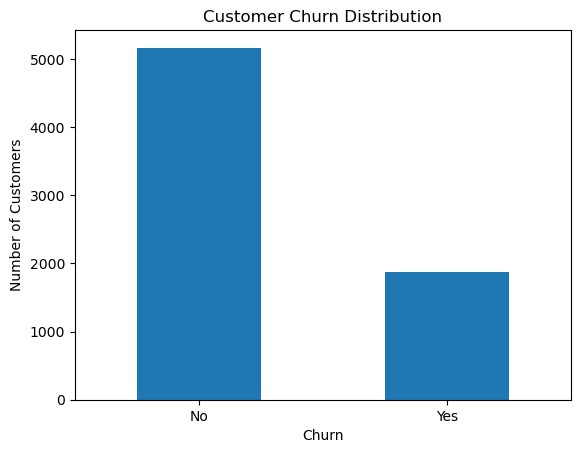

In [9]:
# Visualize customer churn distribution

df["Churn"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


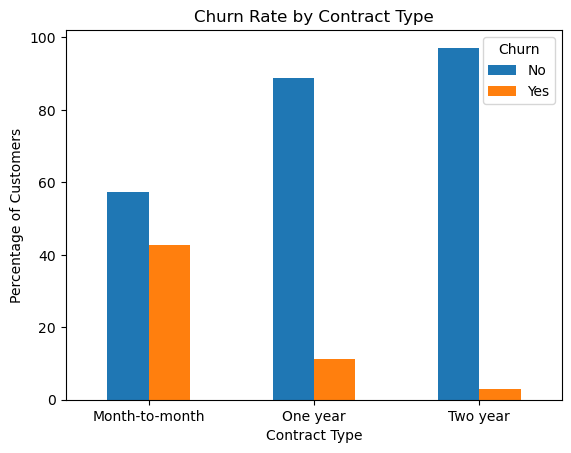

In [10]:
# Analyze churn by contract type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

contract_churn.plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

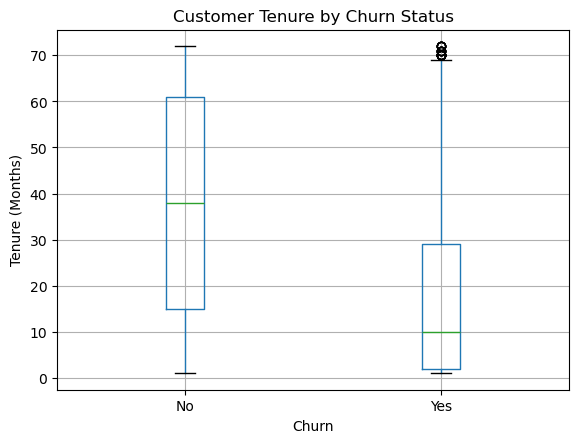

In [11]:
# Analyze customer tenure by churn status

df.boxplot(
    column="tenure",
    by="Churn"
)

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()



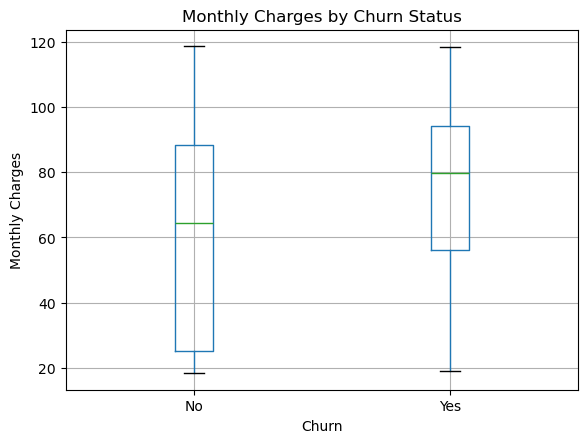

In [12]:
# Analyze monthly charges by churn status

df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

Churn               No    Yes
InternetService              
DSL              81.00  19.00
Fiber optic      58.11  41.89
No               92.57   7.43


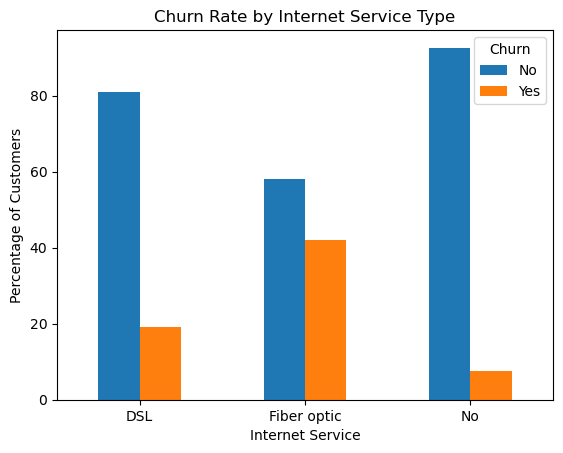

In [13]:
# Analyze churn by internet service type

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

internet_churn.plot(kind="bar")

plt.title("Churn Rate by Internet Service Type")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

In [14]:
# Prepare features and target

# Remove customer ID because it is only an identifier
df_model = df.drop(columns=["customerID"]).copy()

# Convert Churn into numbers
# No = 0, Yes = 1
df_model["Churn"] = df_model["Churn"].map({
    "No": 0,
    "Yes": 1
})

# X = input features
X = df_model.drop(columns=["Churn"])

# y = target variable
y = df_model["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

X shape: (7032, 19)
y shape: (7032,)

Target values:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [15]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5625, 19)
Testing features: (1407, 19)
Training target: (5625,)
Testing target: (1407,)


In [16]:
# Convert categorical variables into numeric dummy variables

X_train_encoded = pd.get_dummies(
    X_train,
    drop_first=True,
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    drop_first=True,
    dtype=int
)

# Make sure training and testing data have identical columns
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

print("Before encoding:")
print(X_train.shape)

print("\nAfter encoding:")
print(X_train_encoded.shape)

X_train_encoded.head()

Before encoding:
(5625, 19)

After encoding:
(5625, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1413,0,65,94.55,6078.75,1,1,1,1,0,1,...,0,0,0,0,0,1,0,1,0,0
7003,0,26,35.75,1022.50,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
3355,0,68,90.20,6297.65,0,1,0,1,0,1,...,0,0,0,0,0,1,0,1,0,0
4494,0,3,84.30,235.05,1,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
3541,0,49,40.65,2070.75,0,1,0,0,1,0,...,0,1,0,0,0,0,0,0,0,0


In [17]:
# Scale numerical features for Logistic Regression

from sklearn.preprocessing import StandardScaler

numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

scaler = StandardScaler()

# Make copies so we keep the original encoded data
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Learn scaling from training data
X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train_encoded[numeric_features]
)

# Apply the same scaling to test data
X_test_scaled[numeric_features] = scaler.transform(
    X_test_encoded[numeric_features]
)

print("Feature scaling completed!")

X_train_scaled[numeric_features].head()

Feature scaling completed!


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
1413,-0.439319,1.321816,0.981556,1.659900
7003,-0.439319,-0.267410,-0.971546,-0.562252
3355,-0.439319,1.444064,0.837066,1.756104
4494,-0.439319,-1.204646,0.641092,-0.908326
3541,-0.439319,0.669826,-0.808787,-0.101561


In [18]:
# Train Logistic Regression model

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
log_model.fit(X_train_scaled, y_train)

# Make predictions on test data
y_pred_log = log_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")

print("\nFirst 10 predictions:")
print(y_pred_log[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

Logistic Regression model trained successfully!

First 10 predictions:
[0 1 0 0 0 0 0 0 1 0]

First 10 actual values:
[0 0 0 1 0 1 0 0 1 0]


In [19]:
# Evaluate Logistic Regression model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Probability of churn
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_log)
precision = precision_score(y_test, y_pred_log)
recall = recall_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log)
roc_auc = roc_auc_score(y_test, y_prob_log)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Logistic Regression Results
---------------------------
Accuracy : 0.8053
Precision: 0.6515
Recall   : 0.5749
F1 Score : 0.6108
ROC-AUC  : 0.8361


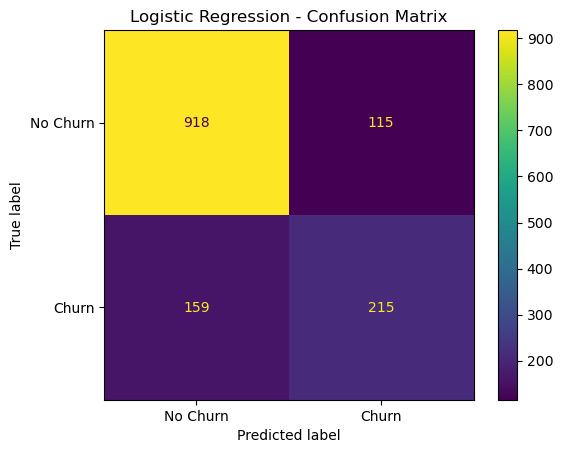

In [20]:
# Create confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_log)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [21]:
# Train Random Forest model

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train_encoded, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test_encoded)

# Get churn probabilities
y_prob_rf = rf_model.predict_proba(X_test_encoded)[:, 1]

print("Random Forest model trained successfully!")

print("\nFirst 10 predictions:")
print(y_pred_rf[:10])


Random Forest model trained successfully!

First 10 predictions:
[0 1 0 0 0 0 0 0 1 0]


In [22]:
# Evaluate Random Forest model

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))

Random Forest Results
---------------------
Accuracy : 0.7875
Precision: 0.6289
Recall   : 0.4893
F1 Score : 0.5504
ROC-AUC  : 0.8199


In [23]:
# Compare model performance

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision,
        rf_precision
    ],
    "Recall": [
        recall,
        rf_recall
    ],
    "F1 Score": [
        f1,
        rf_f1
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc
    ]
})

model_comparison = model_comparison.round(4)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8053,0.6515,0.5749,0.6108,0.8361
1,Random Forest,0.7875,0.6289,0.4893,0.5504,0.8199


                           Feature  Importance
3                     TotalCharges    0.178447
1                           tenure    0.165076
2                   MonthlyCharges    0.151884
25               Contract_Two year    0.059238
10     InternetService_Fiber optic    0.040405
28  PaymentMethod_Electronic check    0.037501
24               Contract_One year    0.029965
13              OnlineSecurity_Yes    0.028844
4                      gender_Male    0.025493
26            PaperlessBilling_Yes    0.023603


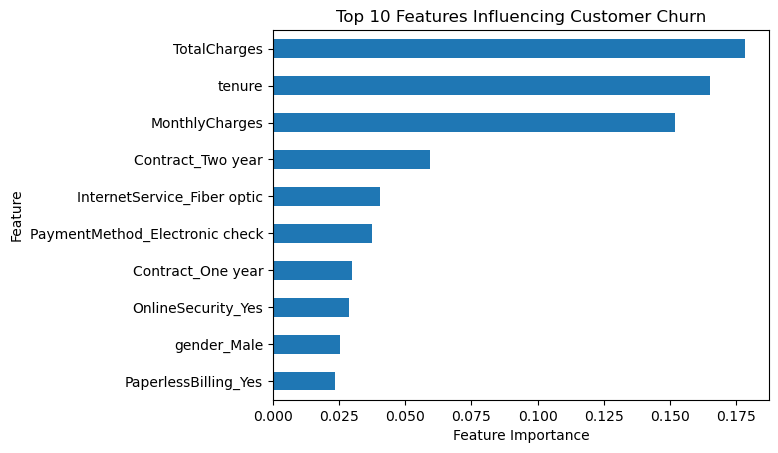

In [24]:
# Find the most important features from Random Forest

feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

print(feature_importance)

feature_importance.sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("Top 10 Features Influencing Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

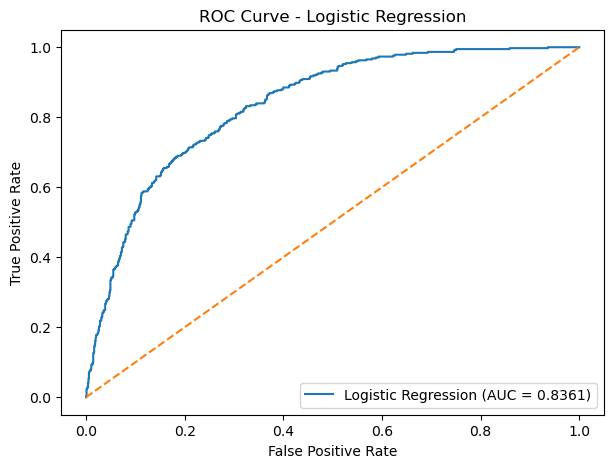

In [25]:
# Plot ROC Curve for Logistic Regression

from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob_log)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()

plt.show()

In [26]:
# Predict churn for one customer

customer = X_test_scaled.iloc[[0]]

# Make prediction
prediction = log_model.predict(customer)[0]

# Get probability of churn
churn_probability = log_model.predict_proba(customer)[0][1]

print("Predicted Churn:", prediction)
print("Churn Probability:", round(churn_probability * 100, 2), "%")

if prediction == 1:
    print("Result: Customer is predicted to CHURN.")
else:
    print("Result: Customer is predicted to STAY.")

Predicted Churn: 0
Churn Probability: 1.8 %
Result: Customer is predicted to STAY.


In [27]:
# Final model summary

print("=" * 45)
print("CUSTOMER CHURN PREDICTION - FINAL RESULTS")
print("=" * 45)

print("\nBest Model: Logistic Regression")

print("\nModel Performance:")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")
print("ROC-AUC  :", round(roc_auc, 4))

print("\nDataset:")
print("Customers analyzed:", len(df))
print("Features used:", X_train_scaled.shape[1])

CUSTOMER CHURN PREDICTION - FINAL RESULTS

Best Model: Logistic Regression

Model Performance:
Accuracy : 80.53 %
Precision: 65.15 %
Recall   : 57.49 %
F1 Score : 61.08 %
ROC-AUC  : 0.8361

Dataset:
Customers analyzed: 7032
Features used: 30


## Conclusion

This project developed a machine learning classification system to predict customer churn using the IBM Telco Customer Churn dataset.

### Key Results
- Analyzed 7,032 customer records after data cleaning.
- Performed exploratory data analysis to examine relationships between churn, contract type, tenure, internet service, and monthly charges.
- Prepared categorical and numerical features for machine learning.
- Trained and compared Logistic Regression and Random Forest classifiers.
- Logistic Regression was the best-performing model.
- Logistic Regression achieved 80.53% accuracy and a ROC-AUC score of 0.8361.
- The model achieved 65.15% precision, 57.49% recall, and a 61.08% F1 score for churn prediction.
- Random Forest feature importance was used to explore influential customer characteristics.

### Business Application
The model can help identify customers with higher churn risk so that a business can prioritize retention efforts, targeted offers, and customer engagement strategies.

### Future Improvements
Future work could include hyperparameter tuning, cross-validation, additional feature engineering, threshold optimization, and testing additional classification models.